In [1]:
import sys
from pathlib import Path
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt
import math, cmath
import sys
import os
import joblib
from pathlib import Path
import pickle
import time
from mpl_toolkits.mplot3d import Axes3D
from scipy.sparse import csr_matrix, coo_matrix,  bmat, diags, identity, issparse, vstack, hstack

In [2]:
#import sys  
sys.path.insert(1,'C:\\Users\\avani\\Desktop\\Spin_Splitting_Ge_ABS')

In [3]:
import Minimal_Model_1D as M
import Minimal_model_1D_1sub as M1sub

In [4]:
hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

In [15]:
### just for particle part, plotting E vs alpha ###

NSM = 300          # in nm
NSC = 2000
N = 2*NSC + NSM
AX = 1
#ALPHAT = 40        # meV-nm
DELTA = 0.165      # in meV
MEFF = 0.023       
PHI = 0.5*np.pi 
LY = 100
OMEGA = 2*4*hbm/LY**2/MEFF
MU_const = 0

ALPHAT = np.linspace(1, 70, 51)

K = 4

Ep_li = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT[i], DELTA, MEFF,  MU_const, phi=PHI)
    
    #print('done')

    Hli = Fli.H_p()

    Eli,V = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=True)
    
    #Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli
    
    if i%5==0:
        print(i)

0
5
10
15
20
25
30
35
40
45
50


In [16]:
print(Ep_li.shape)

(51, 4)


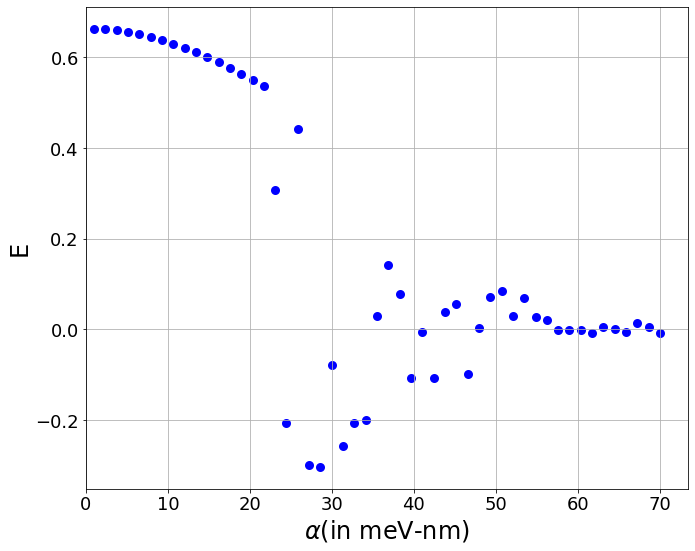

In [18]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]


#plt.subplot(2,1,1)
plt.scatter((ALPHAT[:]), (Ep_li[:,0]), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'E', fontsize=24)
plt.grid(True)
plt.xlim(left=0)


#plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()